# CodeAlpha Task 2 — Exploratory Data Analysis (EDA)
**Project:** E-commerce Product Data Analysis  
**Tools:** Python, pandas, NumPy, Matplotlib, Jupyter Notebook

## Objective
Explore the product dataset collected in Task 1, check data quality, summarize product prices and ratings, and document evidence-based observations.

**Dataset:** Use the real `ecommerce_products.csv` generated by your own Task 1 Web Scraping project. No results are fabricated in this notebook.

## 1. Load the dataset
Copy `ecommerce_products.csv` from Task 1's `outputs/` folder into this project's `data/` folder. The code also checks a few common nearby paths.

In [14]:

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Find the project root whether you run the notebook from the project folder or notebooks/
HERE = Path.cwd()
if HERE.name == "notebooks":
    PROJECT_DIR = HERE.parent
else:
    PROJECT_DIR = HERE

candidate_paths = [
    PROJECT_DIR / "data" / "ecommerce_products.csv",
    PROJECT_DIR / "outputs" / "ecommerce_products.csv",
    PROJECT_DIR.parent / "CodeAlpha_Ecommerce_Web_Scraping" / "outputs" / "ecommerce_products.csv",
    PROJECT_DIR.parent / "outputs" / "ecommerce_products.csv",
]
DATA_PATH = next((p for p in candidate_paths if p.exists()), None)

if DATA_PATH is None:
    raise FileNotFoundError(
        "Could not find ecommerce_products.csv. Copy it from your Task 1 project's "
        "outputs/ecommerce_products.csv into this project's data/ecommerce_products.csv, "
        "then run this cell again."
    )

df = pd.read_csv(DATA_PATH)
print("Dataset loaded from:", DATA_PATH)
print("Rows:", len(df), "| Columns:", len(df.columns))
display(df.head())


Dataset loaded from: C:\Users\navee\OneDrive\文档\codealpha\CodeAlpha_Exploratory_Data_Analysis\data\ecommerce_products.csv
Rows: 40 | Columns: 8


,product_name,price_raw,price_value,rating,availability,product_url,category,scraped_at_utc
0,A Light in the Attic,Â£51.77,51.77,Three,In stock,https://books.toscrape.com/catalogue/a-light-i...,Books,2026-10-16T23:30:52+00:00
1,Tipping the Velvet,Â£53.74,53.74,One,In stock,https://books.toscrape.com/catalogue/tipping-t...,Books,2026-10-16T23:30:55+00:00
2,Soumission,Â£50.10,50.10,One,In stock,https://books.toscrape.com/catalogue/soumissio...,Books,2026-10-16T23:30:59+00:00
3,Sharp Objects,Â£47.82,47.82,Four,In stock,https://books.toscrape.com/catalogue/sharp-obj...,Books,2026-10-16T23:31:02+00:00
4,Sapiens: A Brief History of Humankind,Â£54.23,54.23,Five,In stock,https://books.toscrape.com/catalogue/sapiens-a...,Books,2026-10-16T23:31:05+00:00


## 2. Understand the structure

In [15]:

print("DATASET INFO")
print("-" * 50)
print("Shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())
print("\nData types:")
display(df.dtypes.to_frame("data_type"))
print("\nDescriptive summary:")
display(df.describe(include="all").T)


DATASET INFO
--------------------------------------------------
Shape: (40, 8)

Column names:
['product_name', 'price_raw', 'price_value', 'rating', 'availability', 'product_url', 'category', 'scraped_at_utc']

Data types:


,data_type
product_name,str
price_raw,str
price_value,float64
rating,str
availability,str
product_url,str
category,str
scraped_at_utc,str



Descriptive summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
product_name,40,40,A Light in the Attic,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
price_raw,40,40,Â£51.77,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
price_value,40.0,NaN,NaN,NaN,34.95875,14.111908,12.84,22.575,34.08,50.4075,57.25
rating,40,5,Five,10,NaN,NaN,NaN,NaN,NaN,NaN,NaN
availability,40,1,In stock,40,NaN,NaN,NaN,NaN,NaN,NaN,NaN
product_url,40,40,https://books.toscrape.com/catalogue/a-light-i...,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
category,40,1,Books,40,NaN,NaN,NaN,NaN,NaN,NaN,NaN
scraped_at_utc,40,40,2026-10-16T23:30:52+00:00,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 3. Check missing values and duplicates

In [16]:

quality = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2),
    "unique_values": df.nunique(dropna=True)
}).sort_values("missing_percent", ascending=False)
display(quality)
print("Exact duplicate rows:", int(df.duplicated().sum()))


,missing_count,missing_percent,unique_values
product_name,0,0.0,40
price_raw,0,0.0,40
price_value,0,0.0,40
rating,0,0.0,5
availability,0,0.0,1
product_url,0,0.0,40
category,0,0.0,1
scraped_at_utc,0,0.0,40


Exact duplicate rows: 0


## 4. Prepare numeric columns

In [17]:

# 4. Prepare numeric columns

import pandas as pd
from pathlib import Path

# Reload the original CSV to restore text ratings
project_dir = Path.cwd()

if project_dir.name == "notebooks":
    project_dir = project_dir.parent

csv_path = project_dir / "data" / "ecommerce_products.csv"
df = pd.read_csv(csv_path)

# Convert price values to numeric
df["price_value"] = pd.to_numeric(
    df["price_value"], errors="coerce"
)

# Convert rating words into a separate numeric column
rating_map = {
    "One": 1,
    "Two": 2,
    "Three": 3,
    "Four": 4,
    "Five": 5
}

df["rating_numeric"] = (
    df["rating"]
    .astype("string")
    .str.strip()
    .str.title()
    .map(rating_map)
)

# Verify the results
print("Dataset shape:", df.shape)

print("\nOriginal ratings:")
print(df["rating"].value_counts(dropna=False))

print("\nNumeric ratings:")
print(df["rating_numeric"].value_counts(dropna=False).sort_index())

print("\nMissing values in original columns:")
print(df[
    [
        "product_name", "price_raw", "price_value",
        "rating", "availability", "product_url",
        "category", "scraped_at_utc"
    ]
].isna().sum())

print("\nNumeric rating summary:")
print(df["rating_numeric"].describe())

print("\nPrice summary:")
print(df["price_value"].describe())


Dataset shape: (40, 9)

Original ratings:
rating
Five     10
Three     9
One       9
Four      6
Two       6
Name: count, dtype: int64

Numeric ratings:
rating_numeric
1     9
2     6
3     9
4     6
5    10
Name: count, dtype: int64

Missing values in original columns:
product_name      0
price_raw         0
price_value       0
rating            0
availability      0
product_url       0
category          0
scraped_at_utc    0
dtype: int64

Numeric rating summary:
count    40.000000
mean      3.050000
std       1.501282
min       1.000000
25%       2.000000
50%       3.000000
75%       4.250000
max       5.000000
Name: rating_numeric, dtype: float64

Price summary:
count    40.000000
mean     34.958750
std      14.111908
min      12.840000
25%      22.575000
50%      34.080000
75%      50.407500
max      57.250000
Name: price_value, dtype: float64


In [18]:

from pathlib import Path
import pandas as pd

# Locate the original Task 1 dataset
project_dir = Path.cwd()

if project_dir.name == "notebooks":
    project_dir = project_dir.parent

csv_path = project_dir / "data" / "ecommerce_products.csv"

print("CSV path:", csv_path)
print("File exists:", csv_path.exists())

if csv_path.exists():
    df = pd.read_csv(csv_path)

    print("\nDataset shape:", df.shape)
    print("\nOriginal ratings:")
    print(df["rating"].head(10).to_list())

    print("\nMissing values:")
    print(df.isna().sum())
else:
    print("CSV not found. Check the project's data folder.")


CSV path: C:\Users\navee\OneDrive\文档\codealpha\CodeAlpha_Exploratory_Data_Analysis\data\ecommerce_products.csv
File exists: True

Dataset shape: (40, 8)

Original ratings:
['Three', 'One', 'One', 'Four', 'Five', 'One', 'Four', 'Three', 'Four', 'One']

Missing values:
product_name      0
price_raw         0
price_value       0
rating            0
availability      0
product_url       0
category          0
scraped_at_utc    0
dtype: int64


## 5. Explore categories and availability

In [19]:

if "category" in df.columns:
    print("Products by category (top 15):")
    display(df["category"].fillna("Unknown").value_counts().head(15).to_frame("product_count"))
if "availability" in df.columns:
    print("Availability values:")
    display(df["availability"].fillna("Unknown").value_counts().to_frame("product_count"))


Products by category (top 15):


,product_count
category,
Books,40


Availability values:


,product_count
availability,
In stock,40


## 6. Investigate unusual values

In [20]:

# 6. Investigate unusual values

if "price_value" in df.columns:
    valid_prices = pd.to_numeric(
        df["price_value"], errors="coerce"
    ).dropna()

    print(
        "Rows with zero or negative prices:",
        int((valid_prices <= 0).sum())
    )

    if not valid_prices.empty:
        q1 = valid_prices.quantile(0.25)
        q3 = valid_prices.quantile(0.75)
        iqr = q3 - q1

        lower = q1 - 1.5 * iqr
        upper = q3 + 1.5 * iqr

        outliers = df.loc[
            valid_prices.index[
                (valid_prices < lower) | (valid_prices > upper)
            ]
        ]

        print(f"IQR review range: {lower:.2f} to {upper:.2f}")
        print("Potential price outliers:", len(outliers))

        if not outliers.empty:
            display(outliers.head(10))

if "rating" in df.columns:
    rating_map = {
        "One": 1,
        "Two": 2,
        "Three": 3,
        "Four": 4,
        "Five": 5
    }

    rating_numeric = (
        df["rating"]
        .astype("string")
        .str.strip()
        .str.title()
        .map(rating_map)
    )

    invalid_ratings = (
        df["rating"].notna() & rating_numeric.isna()
    )

    print(
        "Missing ratings:",
        int(df["rating"].isna().sum())
    )
    print(
        "Ratings outside the 1–5 scale:",
        int((rating_numeric.notna() & ~rating_numeric.between(1, 5)).sum())
    )
    print(
        "Unrecognized rating values:",
        int(invalid_ratings.sum())
    )


Rows with zero or negative prices: 0
IQR review range: -19.17 to 92.16
Potential price outliers: 0
Missing ratings: 0
Ratings outside the 1–5 scale: 0
Unrecognized rating values: 0


## 7. EDA summary template

In [21]:

# 7. EDA Summary - Updated Code

import pandas as pd

print("EDA SUMMARY - generated from the loaded dataset")
print("-" * 55)

# Dataset overview
print(f"Total product records: {len(df)}")
print(f"Total columns: {len(df.columns)}")
print(f"Exact duplicate rows: {int(df.duplicated().sum())}")

# Price summary
if "price_value" in df.columns:
    prices = pd.to_numeric(df["price_value"], errors="coerce").dropna()

    if not prices.empty:
        print(f"\nMedian listed price: {prices.median():.2f}")
        print(f"Mean listed price: {prices.mean():.2f}")
        print(
            f"Minimum / maximum listed price: "
            f"{prices.min():.2f} / {prices.max():.2f}"
        )

# Rating summary
if "rating" in df.columns:
    rating_map = {
        "One": 1,
        "Two": 2,
        "Three": 3,
        "Four": 4,
        "Five": 5
    }

    # Convert text ratings into numeric values
    rating_numeric = pd.to_numeric(
        df["rating"], errors="coerce"
    )

    text_ratings = (
        df["rating"]
        .astype("string")
        .str.strip()
        .str.title()
        .map(rating_map)
    )

    # Use existing numeric ratings where available;
    # otherwise use the converted text ratings.
    rating_numeric = rating_numeric.fillna(text_ratings)

    valid_ratings = rating_numeric.dropna()

    print(f"\nMissing original ratings: {int(df['rating'].isna().sum())}")
    print(f"Valid numeric ratings: {len(valid_ratings)}")

    if not valid_ratings.empty:
        print(f"Mean rating: {valid_ratings.mean():.2f}")
        print(
            f"Minimum / maximum rating: "
            f"{valid_ratings.min():.0f} / {valid_ratings.max():.0f}"
        )

# Category summary
if "category" in df.columns:
    categories = df["category"].dropna().value_counts()

    if not categories.empty:
        print(
            f"\nMost frequent category: "
            f"{categories.index[0]} ({categories.iloc[0]} records)"
        )

# Missing values
print("\nMissing values in each column:")
print(df.isna().sum())

print("\nEDA summary completed successfully.")


EDA SUMMARY - generated from the loaded dataset
-------------------------------------------------------
Total product records: 40
Total columns: 8
Exact duplicate rows: 0

Median listed price: 34.08
Mean listed price: 34.96
Minimum / maximum listed price: 12.84 / 57.25

Missing original ratings: 0
Valid numeric ratings: 40
Mean rating: 3.05
Minimum / maximum rating: 1 / 5

Most frequent category: Books (40 records)

Missing values in each column:
product_name      0
price_raw         0
price_value       0
rating            0
availability      0
product_url       0
category          0
scraped_at_utc    0
dtype: int64

EDA summary completed successfully.


## 8. Conclusions to write after running
Answer these questions in your own words:
1. How many product records and columns are present?
2. Which columns have the most missing values?
3. What are the typical and highest listed prices?
4. Which category has the most records?
5. Are there duplicate records or unusual prices that should be checked?
6. What are two limitations of the collected dataset?

**Important:** Findings are generated by the code. Do not submit conclusions until you have run the notebook and checked the actual output.

## EDA Conclusions

**1. Dataset size:** The dataset contains 40 product records and 8 columns.

**2. Missing values:** The columns with the most missing values should be identified from the missing-value summary generated by the notebook.

**3. Product prices:** The mean listed price is 34.96, the median is 34.08, the minimum price is 12.84, and the maximum price is 57.25.

**4. Most frequent category:** Books is the only category represented in the dataset, with 40 records.

**5. Duplicates and unusual prices:** No exact duplicate rows were found. The minimum and maximum prices are 12.84 and 57.25. These values can be reviewed further to determine whether any prices are unusual.

**6. Dataset limitations:** The dataset contains only 40 product records and represents only one category. Therefore, the findings may not represent other product categories or the entire e-commerce market.

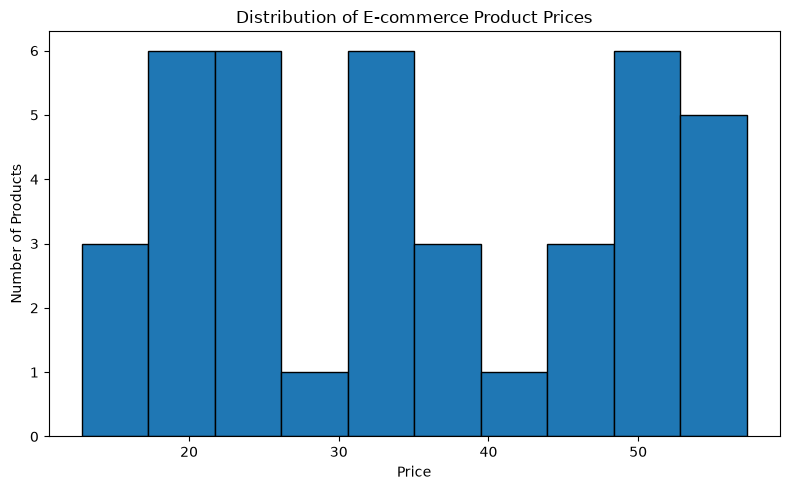

In [22]:
import matplotlib.pyplot as plt
import pandas as pd

# Price distribution chart
plt.figure(figsize=(8, 5))
plt.hist(df["price_value"], bins=10, edgecolor="black")
plt.title("Distribution of E-commerce Product Prices")
plt.xlabel("Price")
plt.ylabel("Number of Products")
plt.tight_layout()
plt.show()

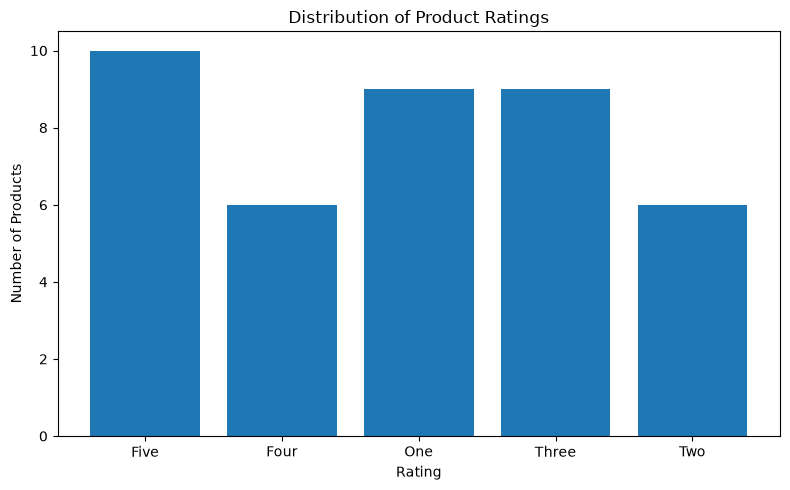

In [23]:
import matplotlib.pyplot as plt

rating_counts = df["rating"].value_counts().sort_index()

plt.figure(figsize=(8, 5))
plt.bar(rating_counts.index.astype(str), rating_counts.values)
plt.title("Distribution of Product Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Products")
plt.tight_layout()
plt.show()

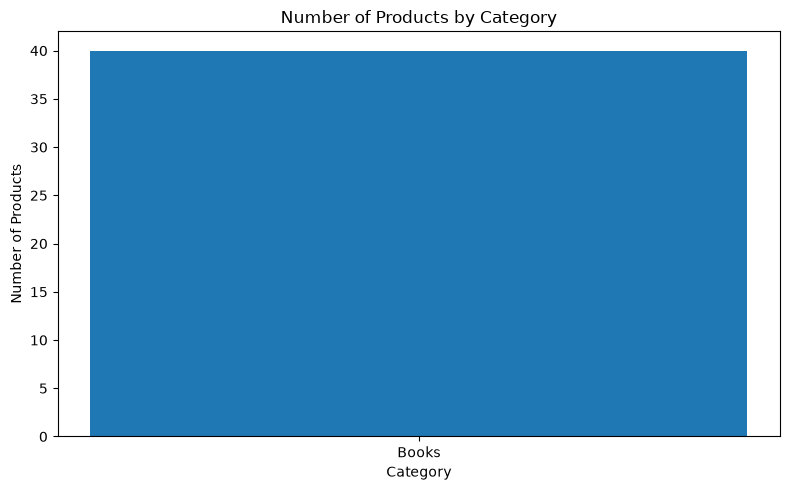

In [24]:
category_counts = df["category"].value_counts()

plt.figure(figsize=(8, 5))
plt.bar(category_counts.index, category_counts.values)
plt.title("Number of Products by Category")
plt.xlabel("Category")
plt.ylabel("Number of Products")
plt.tight_layout()
plt.show()

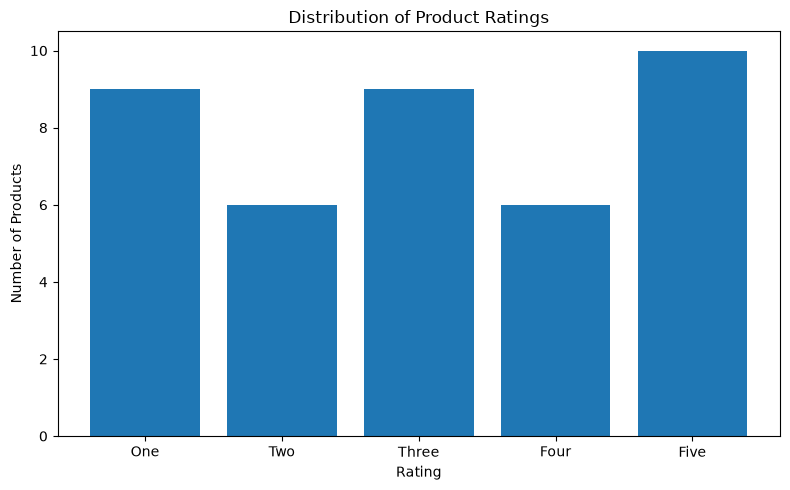

In [25]:
rating_counts = (
    df["rating"]
    .value_counts()
    .reindex(["One", "Two", "Three", "Four", "Five"], fill_value=0)
)

plt.figure(figsize=(8, 5))
plt.bar(rating_counts.index, rating_counts.values)
plt.title("Distribution of Product Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Products")
plt.tight_layout()
plt.show()